# 04 — EDA: Mencari Jawaban "Kenapa Mereka Pergi?"

**Kenapa notebook ini ada?** Notebook 01–03 menyiapkan data. Notebook ini bertanya
pada datanya. Tujuannya bukan membuat banyak grafik, tapi menjawab empat pertanyaan
yang akan dipakai di presentasi:

1. Kapan pelanggan paling sering pergi? (`tenure`)
2. Apa yang membedakan yang pergi dan bertahan? (`Contract`)
3. Apakah harga benar-benar penyebabnya? (`MonthlyCharges`)
4. Layanan mana yang paling berkaitan dengan churn?

Setiap grafik di sini punya satu kalimat kesimpulan. Kalau sebuah grafik tidak
menghasilkan kesimpulan, grafik itu dibuang.

## 0. Persiapan

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

BASE = Path.cwd()
if not (BASE / "data").exists():
    BASE = BASE.parent
print("root project:", BASE)

df = pd.read_csv(BASE / "data" / "clean" / "churn_clean.csv")
print("data:", df.shape)
print("churn rate:", f"{df['Churn'].mean():.2%}")

root project: C:\Users\53\Documents\data sains\machine learning\project ML Supervised
data: (7043, 20)
churn rate: 26.54%


## 1. Kapan pelanggan pergi?

`tenure` (masa berlangganan dalam bulan) kita kelompokkan agar polanya terlihat.
Median tenure adalah 29 bulan, jadi pembagian di bawah masuk akal.

In [2]:
df["kelompok_tenure"] = pd.cut(
    df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6 bln", "7-12 bln", "13-24 bln", "25-48 bln", "49-72 bln"],
)

t = df.groupby("kelompok_tenure", observed=True)["Churn"].agg(
    jumlah="size", churn="sum", rate="mean")
t["rate"] = (t["rate"] * 100).round(1)
t["porsi_churn"] = (t["churn"] / t["churn"].sum() * 100).round(1)
t

,jumlah,churn,rate,porsi_churn
kelompok_tenure,,,,
0-6 bln,1481,784,52.9,41.9
7-12 bln,705,253,35.9,13.5
13-24 bln,1024,294,28.7,15.7
25-48 bln,1594,325,20.4,17.4
49-72 bln,2239,213,9.5,11.4


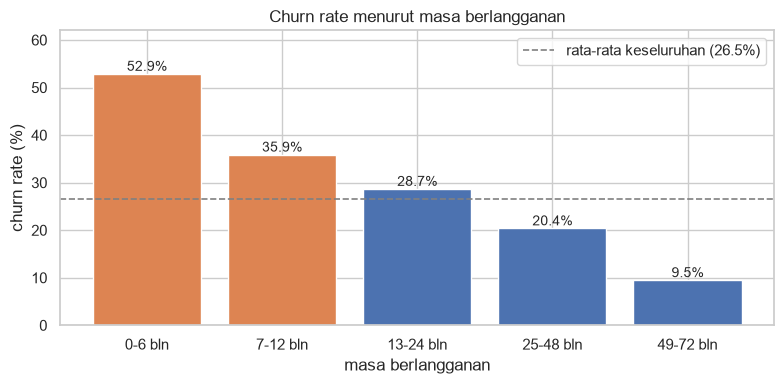

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
warna = ["#dd8452" if r > 30 else "#4c72b0" for r in t["rate"]]
bars = ax.bar(t.index.astype(str), t["rate"], color=warna)
ax.axhline(df["Churn"].mean() * 100, color="gray", linestyle="--", linewidth=1.2,
           label=f"rata-rata keseluruhan ({df['Churn'].mean()*100:.1f}%)")
for b, r in zip(bars, t["rate"]):
    ax.annotate(f"{r:.1f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Churn rate menurut masa berlangganan")
ax.set_xlabel("masa berlangganan")
ax.set_ylabel("churn rate (%)")
ax.set_ylim(0, 62)
ax.legend()
plt.tight_layout()
plt.show()

**Temuan #1 — setengah pelanggan baru pergi dalam 6 bulan.**

| Kelompok | Churn rate | Porsi dari seluruh churn |
|---|---|---|
| **0–6 bulan** | **52,9%** | **41,9%** |
| 7–12 bulan | 35,9% | 13,5% |
| 13–24 bulan | 28,7% | 15,7% |
| 25–48 bulan | 20,4% | 17,4% |
| 49–72 bulan | 9,5% | 11,4% |

Dua angka ini menjawab pertanyaan berbeda dan keduanya penting:

- **Rate 52,9%** → kalau kamu pelanggan baru, risikonya sangat tinggi (per orang)
- **Porsi 41,9%** → kelompok ini penyumbang churn terbesar (secara volume)

Pelanggan yang bertahan 4 tahun ke atas hanya 9,5% yang pergi. Artinya masalahnya
**bukan di semua pelanggan**, tapi terkonsentrasi di masa awal.

## 2. Apa yang membedakan yang pergi dan bertahan?

In [4]:
t = df.groupby("Contract")["Churn"].agg(jumlah="size", churn="sum", rate="mean")
t["rate"] = (t["rate"] * 100).round(1)
t["porsi_churn"] = (t["churn"] / t["churn"].sum() * 100).round(1)
t = t.sort_values("rate", ascending=False)
t

,jumlah,churn,rate,porsi_churn
Contract,,,,
Month-to-month,3875,1655,42.7,88.6
One year,1473,166,11.3,8.9
Two year,1695,48,2.8,2.6


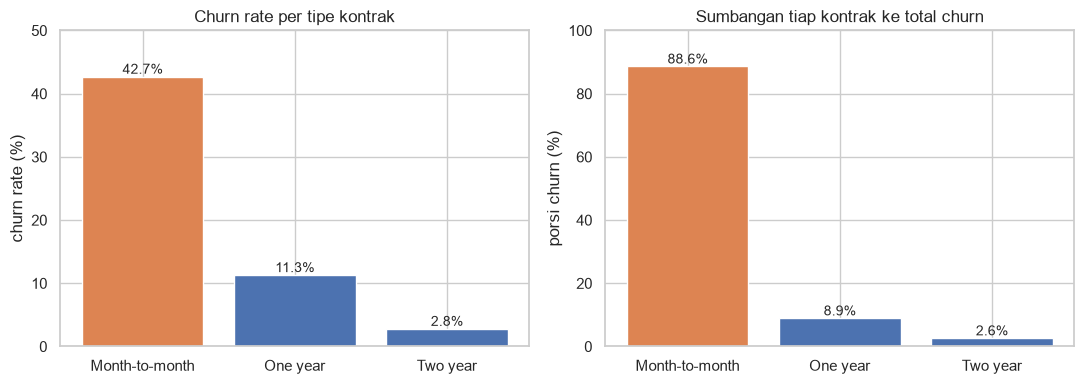

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))

a1.bar(t.index, t["rate"], color=["#dd8452", "#4c72b0", "#4c72b0"])
for i, v in enumerate(t["rate"]):
    a1.annotate(f"{v:.1f}%", (i, v), ha="center", va="bottom", fontsize=10)
a1.set_title("Churn rate per tipe kontrak")
a1.set_ylabel("churn rate (%)")
a1.set_ylim(0, 50)

a2.bar(t.index, t["porsi_churn"], color=["#dd8452", "#4c72b0", "#4c72b0"])
for i, v in enumerate(t["porsi_churn"]):
    a2.annotate(f"{v:.1f}%", (i, v), ha="center", va="bottom", fontsize=10)
a2.set_title("Sumbangan tiap kontrak ke total churn")
a2.set_ylabel("porsi churn (%)")
a2.set_ylim(0, 100)

plt.tight_layout()
plt.show()

**Temuan #2 — kontrak bulanan adalah sumber masalahnya, bukan cuma kelompok berisiko.**

- Churn rate: bulanan **42,7%** vs 1 tahun 11,3% vs 2 tahun **2,8%**
- Porsi churn: bulanan **88,6%**

Kontrak bulanan hanya 55% dari pelanggan, tapi menyumbang 88,6% dari semua yang
pergi. Ini kalimat yang layak masuk slide: *"bukan kelompok berisiko tinggi saja —
ini sumber masalahnya."*

## 3. Apakah benar penyebabnya harga?

Ini pertanyaan yang paling sering dijawab salah. Intuisinya: makin mahal, makin
banyak yang pergi. Mari lihat datanya.

In [6]:
banding = df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2)
banding.index = ["Bertahan (0)", "Churn (1)"]
banding

,tenure,MonthlyCharges,TotalCharges
Bertahan (0),37.57,61.27,2549.91
Churn (1),17.98,74.44,1531.80


C:\Users\53\AppData\Local\Temp\ipykernel_13812\2251186688.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=a1, palette=["#4c72b0", "#dd8452"])


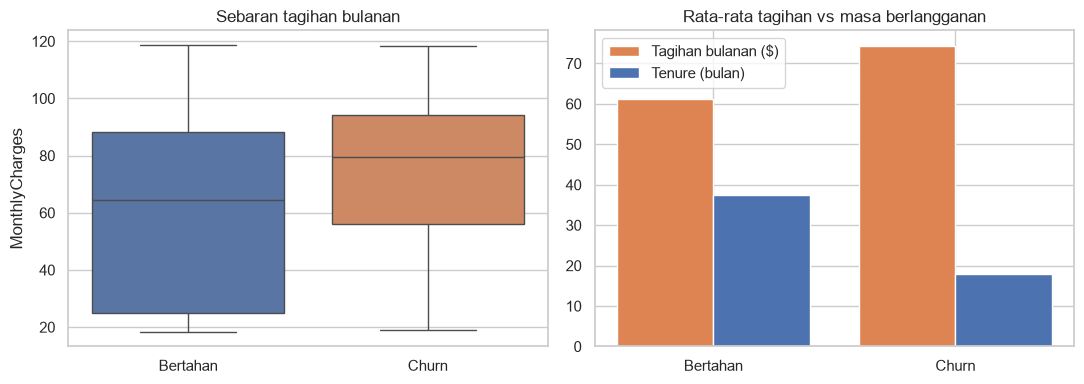

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=a1, palette=["#4c72b0", "#dd8452"])
a1.set_xticks([0, 1])
a1.set_xticklabels(["Bertahan", "Churn"])
a1.set_title("Sebaran tagihan bulanan")
a1.set_xlabel("")

rata = df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean()
x = np.arange(2)
a2.bar(x - 0.2, rata["MonthlyCharges"], 0.4, label="Tagihan bulanan ($)", color="#dd8452")
a2.bar(x + 0.2, rata["tenure"], 0.4, label="Tenure (bulan)", color="#4c72b0")
a2.set_xticks(x)
a2.set_xticklabels(["Bertahan", "Churn"])
a2.set_title("Rata-rata tagihan vs masa berlangganan")
a2.legend()
plt.tight_layout()
plt.show()

**Temuan #3 — yang pergi justru membayar LEBIH MAHAL.**

| | Tenure rata-rata | Tagihan bulanan rata-rata |
|---|---|---|
| Bertahan | 37,6 bulan | **$61,27** |
| Churn | 18,0 bulan | **$74,44** |

Ini membalik dugaan umum. Pelanggan yang pergi membayar ~$13 lebih mahal per bulan.
Jadi **churn bukan soal harga murah**, tapi soal **nilai yang dirasa sebanding
dengan harga**. Yang bayar mahal (biasanya fiber optic) merasa tidak dapat imbalan
setara, lalu pergi.

Perhatikan juga: mereka yang pergi punya tenure jauh lebih pendek (18 vs 37 bulan).
Jadi dua faktor ini saling terkait, bukan berdiri sendiri.

## 4. Layanan mana yang paling berkaitan?

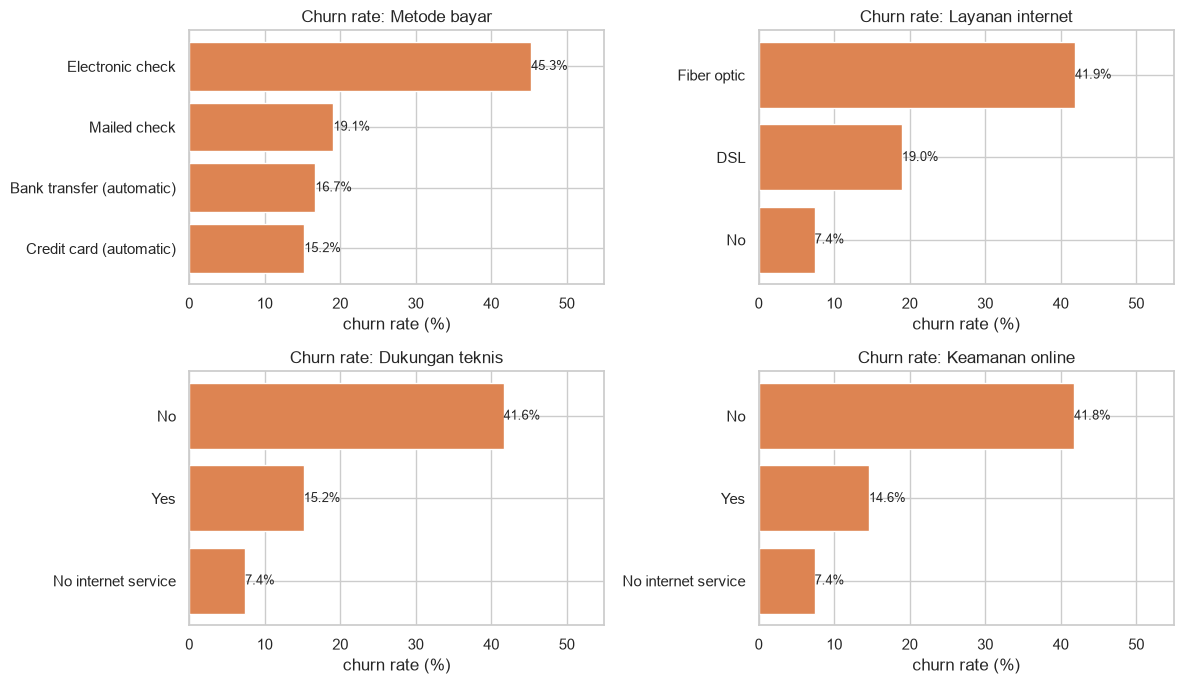

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
pasangan = [
    ("PaymentMethod", "Metode bayar"),
    ("InternetService", "Layanan internet"),
    ("TechSupport", "Dukungan teknis"),
    ("OnlineSecurity", "Keamanan online"),
]

for ax, (kolom, judul) in zip(axes.ravel(), pasangan):
    r = df.groupby(kolom)["Churn"].mean().mul(100).sort_values(ascending=False)
    ax.barh(r.index.astype(str), r.values, color="#dd8452")
    for i, v in enumerate(r.values):
        ax.annotate(f"{v:.1f}%", (v, i), va="center", ha="left", fontsize=9)
    ax.set_title(f"Churn rate: {judul}")
    ax.set_xlabel("churn rate (%)")
    ax.set_xlim(0, 55)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

**Temuan #4 — ada tiga penanda risiko yang sangat jelas.**

| Faktor | Kelompok berisiko | Churn rate |
|---|---|---|
| Metode bayar | Electronic check | **45,3%** |
| Layanan internet | Fiber optic | **41,9%** |
| Dukungan teknis | Tidak punya | **41,6%** |
| Keamanan online | Tidak punya | **41,8%** |

Pembandingnya: pelanggan dengan autodebit ~15–17%, DSL 19,0%, punya tech support
15,2%. Selisihnya bukan sedikit — hampir **tiga kali lipat**.

Satu hal yang perlu hati-hati: ini **korelasi, bukan sebab-akibat**. Kita tidak
bisa bilang "tidak punya tech support menyebabkan churn". Bisa jadi sebaliknya:
yang sudah niat pergi memang tidak memperpanjang layanan tambahan.

## 5. Ringkasan EDA

| # | Temuan | Angka kunci |
|---|---|---|
| 1 | Churn terkonsentrasi di masa awal | 52,9% churn di 6 bulan pertama; 41,9% dari seluruh churn |
| 2 | Kontrak bulanan = sumber masalah | rate 42,7%, porsi **88,6%** |
| 3 | Bukan soal harga | churn bayar $74,44 vs bertahan $61,27 |
| 4 | Tiga penanda risiko | electronic check 45,3%, fiber 41,9%, tanpa tech support 41,6% |

**Yang belum dijawab:** kalau semua faktor ini digabung, seberapa akurat kita bisa
menebak **per orang**? Itu pekerjaan notebook 05.

## 6. Panduan storytelling (dipakai di notebook 06)

Aturan yang dipegang: **satu temuan = satu kalimat**, dan setiap kalimat harus
punya angka pendukung.

| Temuan | Kalimat untuk presentasi |
|---|---|
| #1 | "Setengah pelanggan baru pergi dalam 6 bulan pertama." |
| #2 | "Kontrak bulanan cuma 55% pelanggan, tapi menyumbang 88,6% churn." |
| #3 | "Yang pergi justru yang bayar lebih mahal — jadi ini soal nilai, bukan harga." |
| #4 | "Tanpa tech support, risiko churn hampir tiga kali lipat." |

Hindari kalimat tanpa angka ("banyak pelanggan yang churn") dan hindari angka tanpa
makna ("churn rate 42,7%"). Selalu pasangkan keduanya.